# Sentiment Analysis of News Headlines Using Python

**Research question.** When a lexicon-based tool (VADER) labels news headlines as positive, negative or neutral, do those labels match what the headlines actually mean?

**Dataset.** *News Headlines Dataset for Sarcasm Detection* (Misra & Arora, 2023; Misra & Grover, 2021). It contains 28,619 headlines: real news from *HuffPost* and satirical headlines from *The Onion*. Each one is tagged `is_sarcastic` (1 = The Onion, 0 = HuffPost).
Source: <https://github.com/rishabhmisra/News-Headlines-Dataset-For-Sarcasm-Detection> (file `Sarcasm_Headlines_Dataset_v2.json`, also stored in `data/`).

I picked this dataset on purpose. It is a public collection of news headlines, and it also includes an independent sarcasm label, so I can check one of the known weak spots of automated sentiment analysis (sarcasm, Task 9) with numbers rather than only through anecdotes.

**Notebook outline**
1. Load the data (pandas)
2. Inspect and clean (missing values, duplicates)
3. Apply VADER
4. Classify with documented decision rules
5. Counts and percentages
6. Visualisations
7. Going beyond the output: sarcasm, lexicon coverage, threshold sensitivity
8. Close reading of 10 headlines
9. Limitations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Colours: sentiment is a polarity, so a diverging pair (red <-> blue) with a grey midpoint for neutral
COLOURS = {"negative": "#e34948", "neutral": "#a3a29c", "positive": "#2a78d6"}
ORDER = ["negative", "neutral", "positive"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "font.size": 10})

## 1. Load the dataset

In [2]:
raw = pd.read_json("data/Sarcasm_Headlines_Dataset_v2.json", lines=True)
print("Shape:", raw.shape)
raw.head()

Shape: (28619, 3)


,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clock of hair loss,https://www.theonion.com/thirtysomething-scientists-unveil-doomsday-clock-of-hai-1819586205
1,0,"dem rep. totally nails why congress is falling short on gender, racial equality",https://www.huffingtonpost.com/entry/donna-edwards-inequality_us_57455f7fe4b055bb1170b207
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-veggies-9-delici_b_8899742.html
3,1,inclement weather prevents liar from getting to work,https://local.theonion.com/inclement-weather-prevents-liar-from-getting-to-work-1819576031
4,1,mother comes pretty close to using word 'streaming' correctly,https://www.theonion.com/mother-comes-pretty-close-to-using-word-streaming-cor-1819575546


## 2. Inspect the data and handle missing / duplicate entries

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 28619 entries, 0 to 28618
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   is_sarcastic  28619 non-null  int64
 1   headline      28619 non-null  str  
 2   article_link  28619 non-null  str  
dtypes: int64(1), str(2)
memory usage: 670.9 KB


In [4]:
checks = pd.Series({
    "missing headline (NaN)": raw["headline"].isna().sum(),
    "empty / whitespace-only headline": (raw["headline"].astype(str).str.strip() == "").sum(),
    "missing is_sarcastic": raw["is_sarcastic"].isna().sum(),
    "fully duplicated rows": raw.duplicated().sum(),
    "duplicated article_link": raw["article_link"].duplicated().sum(),
    "duplicated headline text": raw["headline"].str.strip().duplicated().sum(),
})
checks.to_frame("count")

,count
missing headline (NaN),0
empty / whitespace-only headline,0
missing is_sarcastic,0
fully duplicated rows,2
duplicated article_link,2
duplicated headline text,116


There are **no missing values**, but **116 headlines appear more than once**. Most of these are recurring Onion headlines that are reused word for word with different links. The best-known one is *"'no way to prevent this,' says only nation where this regularly happens"*, which The Onion republishes after each mass shooting in the United States. Duplicates would give extra weight to a few headlines, so I keep only the first occurrence of each headline text after stripping whitespace.

In [5]:
dup_examples = (raw.assign(h=raw["headline"].str.strip())
                   .groupby("h").size().sort_values(ascending=False).head(5))
print("Most repeated headlines:\n", dup_examples, "\n")

df = raw.copy()
df["headline"] = df["headline"].str.strip()
df = df.dropna(subset=["headline"])
df = df[df["headline"] != ""]
df = df.drop_duplicates(subset="headline", keep="first").reset_index(drop=True)
df["source"] = df["is_sarcastic"].map({0: "HuffPost (real)", 1: "The Onion (satire)"})

print(f"Rows before cleaning: {len(raw):,}  |  after cleaning: {len(df):,}  |  removed: {len(raw)-len(df)}")
df["source"].value_counts().to_frame("headlines")

Most repeated headlines:
 h
'no way to prevent this,' says only nation where this regularly happens    12
sunday roundup                                                             10
the 20 funniest tweets from women this week                                10
the funniest tweets from parents this week                                  6
the funniest tweets from women this week                                    4
dtype: int64 

Rows before cleaning: 28,619  |  after cleaning: 28,503  |  removed: 116


,headlines
source,
HuffPost (real),14951
The Onion (satire),13552


In [6]:
df["n_words"] = df["headline"].str.split().str.len()
df["n_words"].describe().round(1).to_frame("words per headline")

,words per headline
count,28503.0
mean,10.1
std,3.4
min,2.0
25%,8.0
50%,10.0
75%,12.0
max,151.0


One thing to note before running VADER: **every headline in this dataset is in lower case.** VADER normally treats words in ALL CAPS as more intense ("GREAT" counts for more than "great"), so that cue is missing here. Headlines are also short, about 10 words on average, which leaves VADER very little text to work with.

## 3. Apply VADER

VADER (Valence Aware Dictionary and sEntiment Reasoner; Hutto & Gilbert, 2014) works from a dictionary of about 7,500 words, each with a human-rated valence between −4 and +4. It adjusts those values with a few hand-written rules for negation ("not good"), intensifiers ("very"), contrast ("but"), punctuation ("!") and capitals. For each text it returns `neg`, `neu` and `pos` proportions plus a `compound` score scaled to the range −1 to +1.

In [7]:
analyzer = SentimentIntensityAnalyzer()
scores = df["headline"].apply(analyzer.polarity_scores).apply(pd.Series)
df = pd.concat([df, scores], axis=1)
df[["headline", "neg", "neu", "pos", "compound"]].head(8)

,headline,neg,neu,pos,compound
0,thirtysomething scientists unveil doomsday clock of hair loss,0.504,0.496,0.000,-0.7269
1,"dem rep. totally nails why congress is falling short on gender, racial equality",0.118,0.882,0.000,-0.1531
2,eat your veggies: 9 deliciously different recipes,0.000,0.674,0.326,0.4404
3,inclement weather prevents liar from getting to work,0.311,0.566,0.123,-0.4588
4,mother comes pretty close to using word 'streaming' correctly,0.000,0.714,0.286,0.4939
5,my white inheritance,0.000,1.000,0.000,0.0000
6,5 ways to file your taxes with less stress,0.239,0.761,0.000,-0.3626
7,richard branson's global-warming donation nearly as much as cost of failed balloon trips,0.216,0.784,0.000,-0.5106


## 4. Classify headlines using documented decision rules

I use the thresholds recommended by VADER's authors:

| Rule | Condition on `compound` | Label |
|---|---|---|
| R1 | compound ≥ +0.05 | **positive** |
| R2 | compound ≤ −0.05 | **negative** |
| R3 | −0.05 < compound < +0.05 | **neutral** |

These cut-offs are a convention, not a fact about language. Section 7.3 tests how sensitive the results are to them.

In [8]:
POS_T, NEG_T = 0.05, -0.05

def classify(compound, pos_t=POS_T, neg_t=NEG_T):
    if compound >= pos_t:
        return "positive"
    if compound <= neg_t:
        return "negative"
    return "neutral"

df["label"] = pd.Categorical(df["compound"].apply(classify), categories=ORDER, ordered=True)
df[["headline", "compound", "label"]].sample(8, random_state=7)

,headline,compound,label
25785,new psa reduces accidental staplings by 33 percent,-0.0772,negative
10468,"private prison company backs super pacs for donald trump, senate republicans",0.1027,positive
7050,republican women: a reminder that your party is not for you,0.4019,positive
4507,how where you live affects your child's mental health,0.0000,neutral
22594,trump aims to limit the education department's influence in new order,0.0000,neutral
13439,"meals on wheels volunteers deliver body chocolate, edible underwear to seniors shut in on valentine's day",0.0000,neutral
24241,man has no idea what to do with good mood,0.1779,positive
16964,child boosted on shoulders for better view of man having heart attack,0.7579,positive


## 5. Number and percentage of headlines in each category

In [9]:
summary = (df["label"].value_counts().reindex(ORDER).rename("count").to_frame())
summary["percentage"] = (summary["count"] / summary["count"].sum() * 100).round(2)
summary.loc["total"] = [summary["count"].sum(), 100.0]
summary["count"] = summary["count"].astype(int)
summary.to_csv("outputs/tables/sentiment_distribution.csv")
summary

,count,percentage
label,,
negative,9402,32.99
neutral,10200,35.79
positive,8901,31.23
total,28503,100.00


In [10]:
by_source = pd.crosstab(df["source"], df["label"])
by_source_pct = (pd.crosstab(df["source"], df["label"], normalize="index") * 100).round(1)
by_source_out = by_source.astype(str) + " (" + by_source_pct.astype(str) + "%)"
by_source_out.to_csv("outputs/tables/sentiment_by_source.csv")
by_source_out

label,negative,neutral,positive
source,,,
HuffPost (real),4780 (32.0%),5524 (36.9%),4647 (31.1%)
The Onion (satire),4622 (34.1%),4676 (34.5%),4254 (31.4%)


## 6. Visualisations

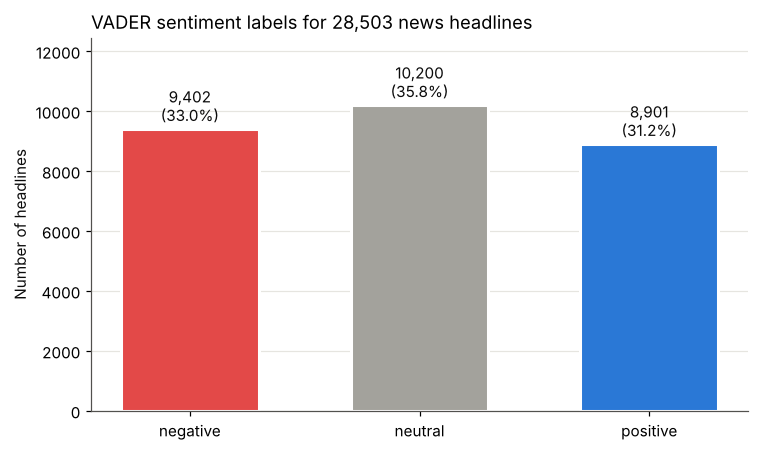

In [11]:
counts = summary.loc[ORDER, "count"]
pcts = summary.loc[ORDER, "percentage"]

fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(ORDER, counts, color=[COLOURS[k] for k in ORDER], width=0.6, edgecolor="white", linewidth=2)
for b, c, p in zip(bars, counts, pcts):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 150, f"{c:,}\n({p:.1f}%)",
            ha="center", va="bottom", fontsize=10, color="#0b0b0b")
ax.set_ylabel("Number of headlines")
ax.set_title(f"VADER sentiment labels for {len(df):,} news headlines", loc="left", fontsize=12)
ax.set_ylim(0, counts.max() * 1.22)
ax.yaxis.grid(True, color="#e6e5e0"); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("outputs/figures/fig1_sentiment_bar.png", dpi=200, bbox_inches="tight"); plt.show()

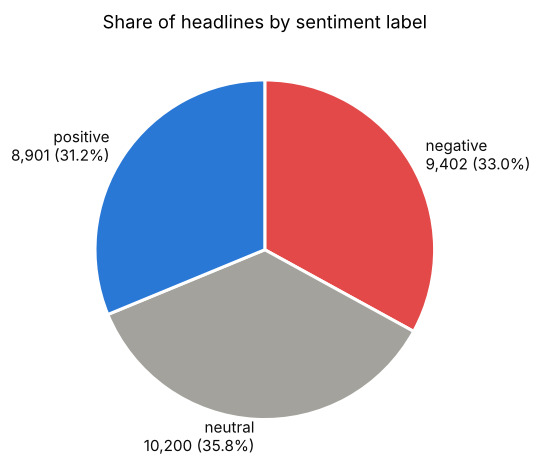

In [12]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(counts, labels=[f"{k}\n{c:,} ({p:.1f}%)" for k, c, p in zip(ORDER, counts, pcts)],
       colors=[COLOURS[k] for k in ORDER], startangle=90, counterclock=False,
       wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"color": "#0b0b0b"})
ax.set_title("Share of headlines by sentiment label", fontsize=12)
plt.tight_layout(); plt.savefig("outputs/figures/fig2_sentiment_pie.png", dpi=200, bbox_inches="tight"); plt.show()

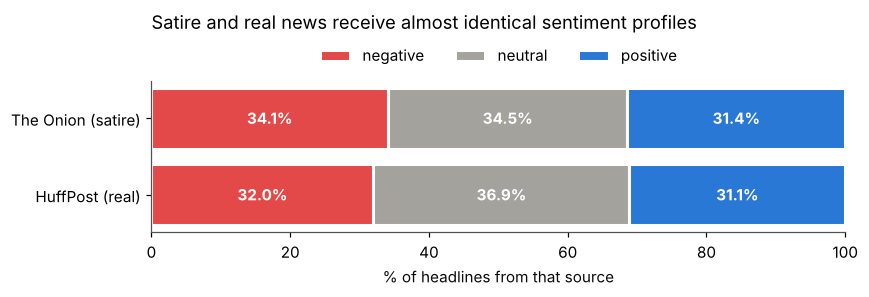

In [13]:
fig, ax = plt.subplots(figsize=(8, 2.8))
left = np.zeros(len(by_source_pct))
for k in ORDER:
    vals = by_source_pct[k].values
    ax.barh(by_source_pct.index, vals, left=left, color=COLOURS[k], edgecolor="white", linewidth=2, label=k)
    for y, (l, v) in enumerate(zip(left, vals)):
        ax.text(l + v/2, y, f"{v:.1f}%", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += vals
ax.set_xlim(0, 100); ax.set_xlabel("% of headlines from that source")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.32), frameon=False)
ax.set_title("Satire and real news receive almost identical sentiment profiles", loc="left", fontsize=12, pad=34)
plt.tight_layout(); plt.savefig("outputs/figures/fig3_sentiment_by_source.png", dpi=200, bbox_inches="tight"); plt.show()

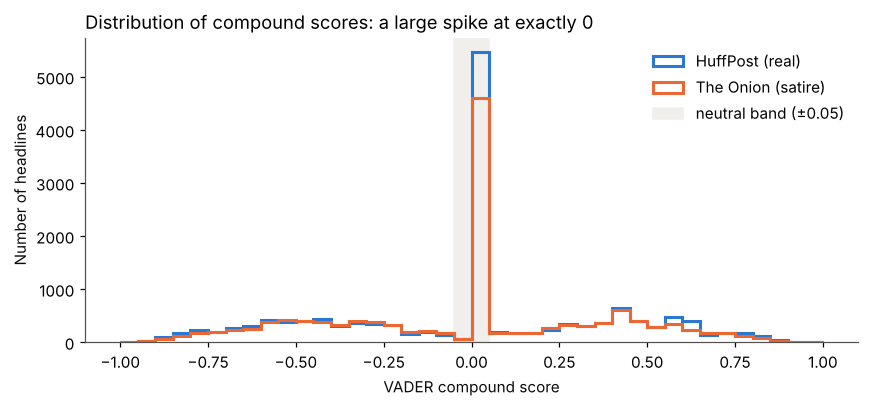

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(-1, 1, 41)
for src, colour in [("HuffPost (real)", "#2a78d6"), ("The Onion (satire)", "#eb6834")]:
    ax.hist(df.loc[df.source == src, "compound"], bins=bins, histtype="step", linewidth=2, color=colour, label=src)
ax.axvspan(NEG_T, POS_T, color="#f0efec", zorder=0, label="neutral band (±0.05)")
ax.set_xlabel("VADER compound score"); ax.set_ylabel("Number of headlines")
ax.set_title("Distribution of compound scores: a large spike at exactly 0", loc="left", fontsize=12)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("outputs/figures/fig4_compound_distribution.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Interpreting the output rather than just reporting it

### 7.1 Does VADER notice sarcasm?
If VADER picked up the mocking tone of satire, Onion headlines would come out more negative, or at least different from real news. They do not. The two sources have nearly the same label percentages and mean scores (table below). A chi-square test checks whether label distribution depends on source.

In [15]:
from scipy.stats import chi2_contingency
chi2, p, dof, _ = chi2_contingency(by_source)
n = by_source.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(by_source.shape) - 1)))
print(f"chi2 = {chi2:.1f}, dof = {dof}, p = {p:.4f}, Cramér's V = {cramers_v:.3f}")
df.groupby("source")["compound"].agg(["mean", "median", "std"]).round(3)

chi2 = 21.9, dof = 2, p = 0.0000, Cramér's V = 0.028


,mean,median,std
source,,,
HuffPost (real),-0.011,0.0,0.397
The Onion (satire),-0.016,0.0,0.387


With about 28,500 headlines, even a tiny difference can come out "statistically significant", so the effect size matters more than the p-value. **Cramér's V is about 0.03, which is a negligible effect.** In practice, VADER gives deliberately ironic headlines the same mix of labels as straight news. The tool reacts to *which words* appear, not to *what the writer is doing* with them.

### 7.2 How many "neutral" headlines are really neutral?
A neutral label can mean two different things: (a) the headline really is balanced or purely factual, or (b) **none of its words are in VADER's dictionary.** The second case is a gap in coverage, not a judgement about meaning.

In [16]:
lex = analyzer.lexicon
def lexicon_hits(text):
    toks = [t.strip(".,!?:;'\"()[]") for t in text.split()]
    return [t for t in toks if t in lex]

df["lex_words"] = df["headline"].apply(lexicon_hits)
df["n_lex"] = df["lex_words"].str.len()

zero = (df["compound"] == 0).sum()
no_lex = (df["n_lex"] == 0).sum()
print(f"Neutral headlines:                      {(df.label=='neutral').sum():,}")
print(f"  ...with compound exactly 0.0:         {zero:,}")
print(f"  ...with no sentiment word at all:     {no_lex:,} ({no_lex/(df.label=='neutral').sum()*100:.1f}% of neutrals)")

for w in ["dies", "died", "shooting", "hurricane", "flood", "layoffs", "deported", "killed", "cancer", "war"]:
    print(f"  '{w}' in lexicon? {w in lex}" + (f"  (valence {lex[w]:+.1f})" if w in lex else ""))

Neutral headlines:                      10,200
  ...with compound exactly 0.0:         9,868
  ...with no sentiment word at all:     9,755 (95.6% of neutrals)
  'dies' in lexicon? False
  'died' in lexicon? True  (valence -2.6)
  'shooting' in lexicon? False
  'hurricane' in lexicon? False
  'flood' in lexicon? False
  'layoffs' in lexicon? False
  'deported' in lexicon? False
  'killed' in lexicon? True  (valence -3.5)
  'cancer' in lexicon? True  (valence -3.4)
  'war' in lexicon? True  (valence -2.9)


In [17]:
# Headlines that contain obviously negative news events but have no lexicon hits
event_words = r"\b(?:dies|shooting|layoffs|lays off|flood|hurricane|deported)\b"
missed = df[(df.label == "neutral") & df.headline.str.contains(event_words)]
print(f"{len(missed):,} neutral-labelled headlines mention dies / shooting / layoffs / flood / hurricane / deported")
missed[["source", "headline", "compound"]].sample(10, random_state=3)

95 neutral-labelled headlines mention dies / shooting / layoffs / flood / hurricane / deported


,source,headline,compound
14627,HuffPost (real),"barksdale, inspiration behind characters on 'the wire,' dies in federal prison",0.0258
5369,HuffPost (real),third whale this year dies at seaworld san antonio,0.0000
27768,The Onion (satire),nigel farage dies of milkshake wounds,0.0000
2913,HuffPost (real),congressman calls for investigation into alton sterling shooting,0.0000
6098,The Onion (satire),americans hopeful this will be last mass shooting before they stop on their own for no reason,-0.0258
2406,HuffPost (real),will smith shooting scene witness shocked by alleged shooter cardell hayes' calm behavior,0.0000
22143,HuffPost (real),"man dies after telling police who chased him 'i can't breathe,' sources say",0.0000
19104,The Onion (satire),company lacks manpower to complete newest round of layoffs,0.0000
20332,The Onion (satire),wall street journal lays off 150 stipple-portrait artists,0.0000
11774,The Onion (satire),texans brace for president's response to hurricane,0.0000


This is an important result. **VADER's dictionary contains "died" but not "dies"**, and "shooting", "hurricane", "flood", "layoffs" and "deported" are not in it either. Death notices and disaster reports, which most readers would call clearly negative news, are therefore often labelled *neutral*. Part of the large neutral category comes from gaps in the dictionary, not from neutral reporting.

### 7.3 Sensitivity to the decision rule
The ±0.05 thresholds are a convention. If I widen the neutral band, the category sizes change quite a lot, so any claim like "X % of headlines are positive" depends on a researcher's choice as well as on the text.

In [18]:
rows = []
for t in [0.05, 0.10, 0.20, 0.30, 0.50]:
    lab = df["compound"].apply(lambda c: classify(c, t, -t))
    vc = lab.value_counts(normalize=True).reindex(ORDER) * 100
    rows.append({"threshold (±)": t, **vc.round(1).to_dict()})
sens = pd.DataFrame(rows).set_index("threshold (±)")
sens.to_csv("outputs/tables/threshold_sensitivity.csv")
sens

,negative,neutral,positive
threshold (±),,,
0.05,33.0,35.8,31.2
0.10,31.9,38.2,29.9
0.20,29.2,43.3,27.5
0.30,24.4,52.3,23.4
0.50,13.8,74.7,11.5


## 8. Close reading of 10 headlines

I chose 10 headlines to cover the main situations: cases where VADER is clearly right, missing vocabulary, a word meaning one thing in VADER's dictionary and another in the headline, proper nouns, sarcasm, implied meaning, and mixed sentiment. For each one I show the words VADER actually used and compare its label with my own reading of the headline.

In [19]:
selected = [
    ("student killed herself after university mishandled her rape report: suit", "negative", "Correct. Tragic event; 'killed' and 'rape' carry the score."),
    ("mexico mayor killed less than a day after taking office", "negative", "Correct. Single strong cue ('killed') matches the meaning."),
    ("british singer and tv host cilla black dies at 72", "negative", "Wrong. 'dies' is missing from the lexicon (only 'died' is listed), so a death notice is labelled neutral."),
    ("how fake meat may change our future thanksgiving dinners", "neutral", "Wrong. 'fake' means plant-based, not deceitful; a word-sense error turns a neutral food story negative."),
    ("duke students refuse to read 'fun home' over gay themes, nudity", "negative", "Wrong. 'Fun Home' is a book title; 'fun' should not count. The story is about conflict/censorship."),
    ("bob hope happy to see so many troops in heaven", "negative", "Wrong. 'Hope' is a surname and 'happy' is ironic; satire about soldiers' deaths scores +0.87."),
    ("report: underfunded public schools lacking basic support systems leave students perfectly prepared for rest of life", "negative", "Wrong. Sarcasm: 'perfectly prepared' means the opposite of what it says."),
    ("'no way to prevent this,' says only nation where this regularly happens", "negative", "Wrong. Bitter satire about gun violence. VADER reads 'no' as negating 'prevent' and lands just above zero (+0.03): neutral."),
    ("boeing lays off only guy who knows how to keep wings on plane", "negative", "Wrong. Implied negativity (danger, incompetence) is expressed through situation, not vocabulary."),
    ("why i'm thinking of separating from a wonderful man after 27 years together", "negative / mixed", "Debatable. 'wonderful' describes the man, but the headline is about a painful separation."),
]

def drivers(text):
    toks = [t.strip(".,!?:;'\"()[]") for t in text.split()]
    return ", ".join(f"{t} ({lex[t]:+.1f})" for t in toks if t in lex) or "— none —"

close = pd.DataFrame(selected, columns=["headline", "human_reading", "assessment"])
close = close.merge(df[["headline", "source", "compound", "label"]], on="headline", how="left")
close["words_VADER_used"] = close["headline"].apply(drivers)
close["agrees"] = [h.startswith(str(l)) for h, l in zip(close.human_reading, close.label)]
close.index = range(1, len(close) + 1)
close.to_csv("outputs/tables/close_reading_10_headlines.csv")
close[["headline", "source", "compound", "label", "words_VADER_used", "human_reading", "agrees"]]

,headline,source,compound,label,words_VADER_used,human_reading,agrees
1,student killed herself after university mishandled her rape report: suit,HuffPost (real),-0.8807,negative,"killed (-3.5), rape (-3.7)",negative,True
2,mexico mayor killed less than a day after taking office,HuffPost (real),-0.6705,negative,killed (-3.5),negative,True
3,british singer and tv host cilla black dies at 72,HuffPost (real),0.0000,neutral,— none —,negative,False
4,how fake meat may change our future thanksgiving dinners,HuffPost (real),-0.4767,negative,fake (-2.1),neutral,False
5,"duke students refuse to read 'fun home' over gay themes, nudity",HuffPost (real),0.2732,positive,"refuse (-1.2), fun (+2.3)",negative,False
6,bob hope happy to see so many troops in heaven,The Onion (satire),0.8720,positive,"hope (+1.9), happy (+2.7), heaven (+2.3)",negative,False
7,report: underfunded public schools lacking basic support systems leave students perfectly prepared for rest of life,The Onion (satire),0.8225,positive,"support (+1.7), leave (-0.2), perfectly (+3.2), prepared (+0.9)",negative,False
8,"'no way to prevent this,' says only nation where this regularly happens",The Onion (satire),0.0258,neutral,"no (-1.2), prevent (+0.1)",negative,False
9,boeing lays off only guy who knows how to keep wings on plane,The Onion (satire),0.0000,neutral,— none —,negative,False
10,why i'm thinking of separating from a wonderful man after 27 years together,HuffPost (real),0.5719,positive,wonderful (+2.7),negative / mixed,False


In [20]:
print(f"VADER agrees with the human reading on {close.agrees.sum()} of {len(close)} hand-picked headlines.")
for i, r in close.iterrows():
    print(f"\n{i}. \"{r.headline}\"\n   VADER: {r.label} ({r.compound:+.3f}) | Human: {r.human_reading}\n   {r.assessment}")

VADER agrees with the human reading on 2 of 10 hand-picked headlines.

1. "student killed herself after university mishandled her rape report: suit"
   VADER: negative (-0.881) | Human: negative
   Correct. Tragic event; 'killed' and 'rape' carry the score.

2. "mexico mayor killed less than a day after taking office"
   VADER: negative (-0.670) | Human: negative
   Correct. Single strong cue ('killed') matches the meaning.

3. "british singer and tv host cilla black dies at 72"
   VADER: neutral (+0.000) | Human: negative
   Wrong. 'dies' is missing from the lexicon (only 'died' is listed), so a death notice is labelled neutral.

4. "how fake meat may change our future thanksgiving dinners"
   VADER: negative (-0.477) | Human: neutral
   Wrong. 'fake' means plant-based, not deceitful; a word-sense error turns a neutral food story negative.

5. "duke students refuse to read 'fun home' over gay themes, nudity"
   VADER: positive (+0.273) | Human: negative
   Wrong. 'Fun Home' is a book 

**Interpretation.** I picked these ten to probe weak spots, so the 2/10 agreement rate is **not** an estimate of VADER's overall accuracy. What the examples show is *how* the errors happen:

* **Correct cases (1–2)** are explicit: one strong emotional word ("killed") matches the meaning of the whole headline.
* **Missing vocabulary (3)**: everyday news words such as "dies", "shooting" and "lays off" are not in the dictionary, so the headline reads as "no sentiment".
* **Word sense and named entities (4–6)**: VADER cannot tell *fake* meat (plant-based) from *fake* news (deceitful), or the book *Fun Home* and the comedian Bob *Hope* from the ordinary words "fun" and "hope".
* **Sarcasm and irony (6–8)**: in satire, positive words carry negative meaning. Example 7 gets a strongly positive score (+0.82) for a bitter comment on school underfunding.
* **Implied meaning (8–9)**: the negativity comes from situation and world knowledge (a plane losing its wings, a country that does nothing about repeated shootings), not from emotional words.
* **Mixed or contested meaning (10)**: one compound score cannot capture "a wonderful man" and "separating" at the same time. Readers might also disagree with each other here.

## 9. Limitations of automated sentiment analysis

1. **Sarcasm and irony.** Lexicon methods read words at face value. Section 7.1 shows VADER gives satire and real news almost the same distribution (Cramér's V ≈ 0.03).
2. **Ambiguity.** The same word changes meaning with its sense ("fake meat") or when it is part of a name ("Bob Hope", "Fun Home", and in other headlines "Mia Love").
3. **Context and world knowledge.** Headlines are short and rely on what the reader already knows. "Laying off the only person who can keep wings on a plane" is alarming only if you know what wings do.
4. **Dictionary coverage.** Many neutral labels come from missing words (Section 7.2), which inflates the neutral category and hides negative news.
5. **"Sentiment" of what?** A headline about a tragedy can be *about* a negative event while being written in neutral journalistic language. VADER mixes up the topic, the writer's stance and the likely effect on the reader.
6. **Arbitrary thresholds.** The category sizes shift a lot with the cut-off (Section 7.3).
7. **Preprocessing.** The dataset is all lower case, so VADER's capitalisation rule never applies.
8. **No ground-truth sentiment labels.** The dataset labels sarcasm, not sentiment, so this study can show VADER's blind spots but cannot measure its overall accuracy. A proper evaluation would need people to annotate a random sample.

In [21]:
df.drop(columns=["lex_words"]).to_csv("outputs/tables/headlines_with_vader_scores.csv", index=False)
print("Saved:", "outputs/tables/headlines_with_vader_scores.csv")

Saved: outputs/tables/headlines_with_vader_scores.csv


## References
* Hutto, C. J., & Gilbert, E. (2014). VADER: A parsimonious rule-based model for sentiment analysis of social media text. *Proceedings of the International AAAI Conference on Web and Social Media, 8*(1), 216–225.
* Misra, R., & Arora, P. (2023). Sarcasm detection using news headlines dataset. *AI Open, 4*, 13–18.
* Misra, R., & Grover, J. (2021). *Sculpting Data for ML: The first act of Machine Learning.* ISBN 9798585463570.